# 🎓 KOE Green Jacket PPE AI Detection System
## 📌 Master Engineering & Delivery Project Plan Notebook
### Revision 2.0 — Updated Schedule & Team Structure

---

### **Executive Project Information**
| Field | Details |
| :--- | :--- |
| **Project Title** | Edge-AI PPE Compliance Detection for KOE Workshop Entrances |
| **Target Class** | `KOE Green Jacket` |
| **Edge Platform** | RDK X5 — 10 TOPS BPU (Horizon Robotics Bayes) |
| **Vision Sensor** | USB Webcam (720p/1080p @ 30 FPS via OpenCV / V4L2) |
| **Middleware & Runtime** | **ROS2 Humble (Ubuntu 22.04 LTS on RDK X5)** |
| **Model** | YOLOv8n (primary) · YOLOv11n (secondary benchmark) |
| **First Deployment Milestone** | **Week 8** |
| **Final Delivery** | **Week 14** |
| **Team Size** | 1 PM/Lead + 1 Assistant + 2 Dataset + 1 Paperwork = 5 members |
| **Reference** | [D-Robotics rdk_model_zoo](https://github.com/D-Robotics/rdk_model_zoo) |


## 1. 🧠 YOLO Model Recommendation

| Architecture | BPU Toolchain | Size | Stability | Verdict |
| :--- | :--- | :--- | :--- | :--- |
| YOLOv3/v4/v5 | Legacy | Large | Outdated | ❌ Avoid |
| YOLOv7 | Reparam issues | Medium | Unstable on BPU | ❌ Avoid |
| **YOLOv8n** | **100% BPU ops** | **3.2M params** | **Rock solid** | ✅ **PRIMARY** |
| YOLOv9/v10 | CPU fallback ops | Variable | Unstable | ❌ Avoid |
| YOLOv11n | Mostly supported | 2.6M params | Good | 🔵 Secondary |
| YOLOv12+ | Unsupported | Untested | None | ❌ Avoid |

> **Decision:** Use `YOLOv8n`. Its C2f/SPPF blocks map 100% to Horizon BPU PEs.  
> Scale up to `YOLOv8s` only if mAP falls below 85% after augmentation tuning.


## 2. 👥 Revised Team Structure & Task Delegation

### Team Roles (5 Members)

| # | Role | Members | Core Responsibilities |
| :---: | :--- | :--- | :--- |
| 1 | **Project Manager + System Developer** | **PM Lead** | End-to-end delivery, ROS2 Humble edge system development (camera node, BPU detector node, access controller node), Colab AI training, AI model training from prepared dataset, NPU model conversion |
| 2 | **Assistant PM** | **Member 1** | Supports PM Lead in system dev tasks, sets up Horizon OpenExplorer toolchain early, handles BPU conversion & benchmarking, assists with Colab training |
| 3 | **Dataset Specialist** | **Member 3** | On-site image capture, raw dataset curation, upload to Roboflow |
| 4 | **Dataset Specialist** | **Member 4** | On-site image capture, Roboflow bounding box annotation, quality review |
| 5 | **Documentation & Support** | **Member 5** | Project proposals, progress reports, presentation slides, final report. Assists Members 3 & 4 on annotation when no paperwork pending |

### ⚠️ Critical Constraint
> **System development is handled exclusively by PM Lead.**  
> Member 1 assists with toolchain setup and BPU conversion but does NOT independently develop the inference application.

### RACI Matrix

| Activity | PM Lead | Member 1 | Member 3 | Member 4 | Member 5 |
| :--- | :---: | :---: | :---: | :---: | :---: |
| Project Governance & Charter | **A/R** | C | I | I | C |
| On-site Image Capture | I | I | **A/R** | R | C |
| Roboflow Annotation | C | I | R | **A/R** | C |
| Data Augmentation & Export | **A** | C | R | R | I |
| Colab Model Training | **A/R** | R | I | I | I |
| ONNX Export | **A/R** | C | I | I | I |
| System Architecture | **A/R** | C | I | I | I |
| BPU Toolchain Setup | **A** | **R** | I | I | I |
| hb_mapper INT8 Quantization | **A** | **R** | I | I | I |
| Webcam Inference Pipeline | **A/R** | C | I | I | I |
| Multi-Detection OSD UI | **A/R** | C | I | I | I |
| Week 8 First Deployment | **A/R** | R | I | I | I |
| Post-Deploy Optimization | **A/R** | R | C | C | I |
| Proposals & Reports | C | I | I | I | **A/R** |
| Final Presentation Slides | C | C | I | I | **A/R** |
| Final QA & Acceptance | **A** | R | R | R | R |


In [1]:
# Cell 1: Install Dependencies & Environment Setup
import subprocess, sys

_pkgs = ['numpy', 'pandas', 'matplotlib', 'seaborn']
for _p in _pkgs:
    try:
        __import__(_p)
    except ImportError:
        print(f'Installing {_p}...')
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', _p, '-q'])

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#cbd5e1'
plt.rcParams['axes.linewidth'] = 1.0

ROLE_COLORS = {
    'PM Lead + Mbr1': '#0f766e',
    'Member 3 (Dataset)': '#2563eb',
    'Member 4 (Dataset)': '#7c3aed',
    'Member 5 (Docs)': '#ea580c',
    'All Team': '#475569'
}
print('Environment ready.')

Environment ready.


## 3. 📅 Revised 14-Week Schedule

| Phase | Weeks | Goal |
| :--- | :---: | :--- |
| **Dataset Sprint** | 1 – 4 | 400+ images collected, fully annotated in Roboflow, dataset V1 frozen |
| **Training & Conversion** | 4 – 6 | YOLOv8n trained on Colab (mAP ≥ 90%), exported to ONNX, BPU .bin compiled |
| **System Dev Phase 1** | 1 – 7 | Webcam pipeline, inference engine, basic OSD UI ready |
| **🎯 FIRST DEPLOYMENT** | **Week 8** | Full end-to-end system running on RDK X5 BPU at workshop entrance |
| **Optimization Sprint** | 8 – 11 | Dataset expansion, re-training, threshold tuning, edge case fixing |
| **System Dev Phase 2** | 9 – 12 | Access control policy, logging, multi-student stress test |
| **Final QA & Docs** | 12 – 14 | Acceptance testing, final report, slides, handover |


<string>:84: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
C:\Users\Victus\OneDrive\Desktop\GENE_ProjectAI\scripts\execute_notebooks.py:40: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  fig.savefig(buf, format="png", bbox_inches="tight", dpi=150)


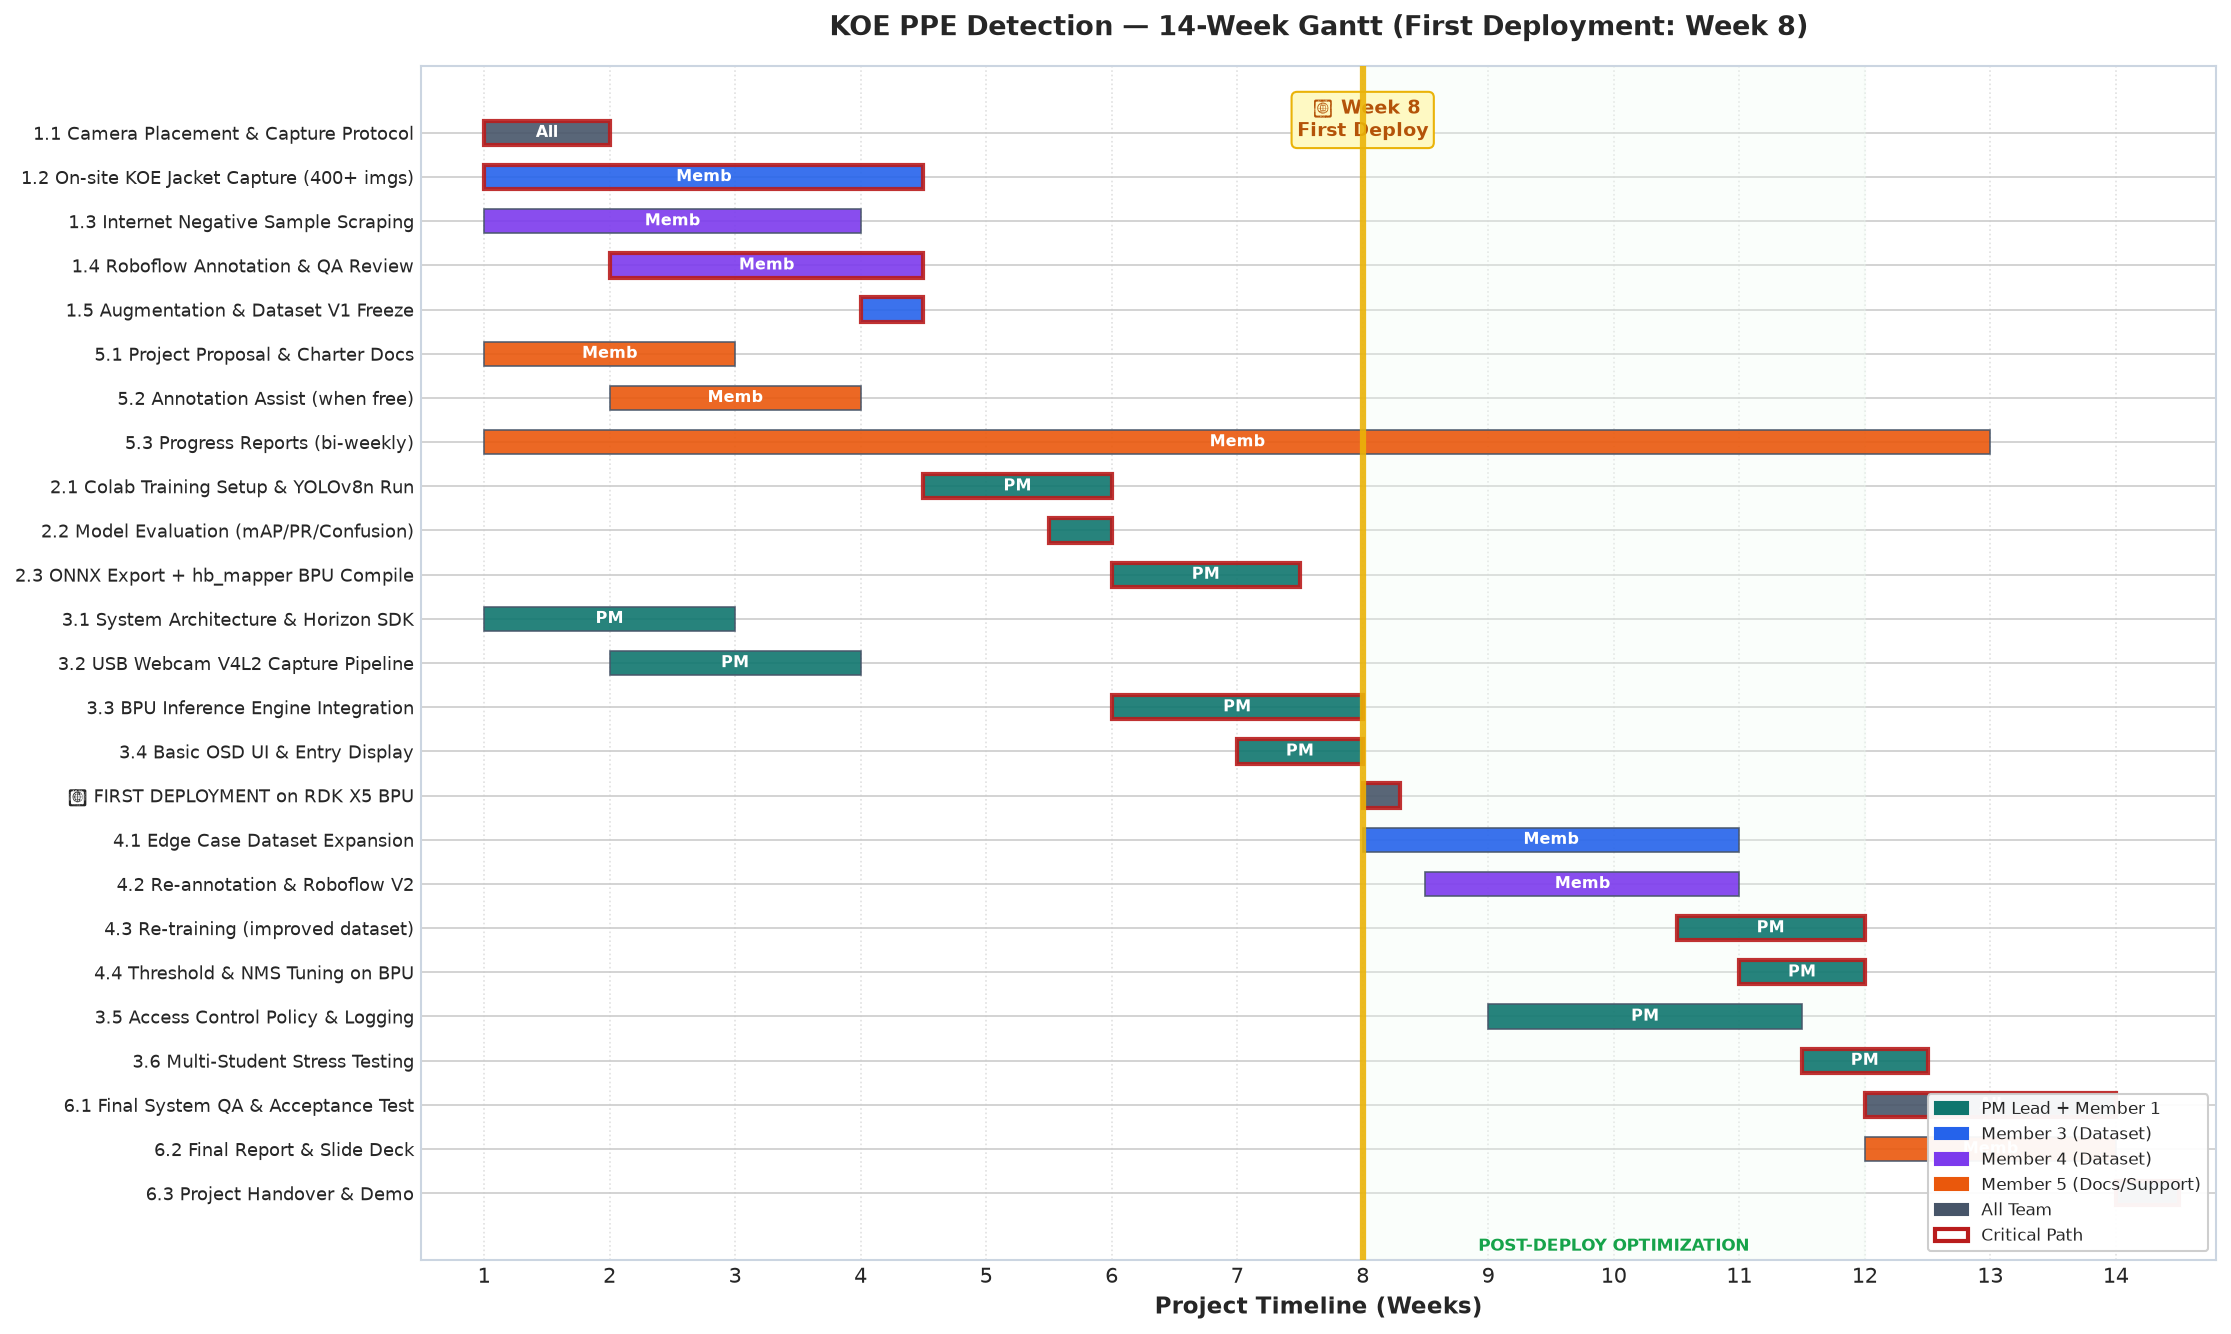

In [2]:
# Cell 2: Revised 14-Week Gantt Chart — First Deployment at Week 8
fig, ax = plt.subplots(figsize=(15, 9), dpi=200)

schedule_data = [
    # Phase 1: Dataset Sprint (Members 3, 4, 5)
    {'Task':'1.1 Camera Placement & Capture Protocol',  'Owner':'All Team',             'Start':1.0,  'Dur':1.0,  'Crit':True},
    {'Task':'1.2 On-site KOE Jacket Capture (400+ imgs)','Owner':'Member 3 (Dataset)',  'Start':1.0,  'Dur':3.5,  'Crit':True},
    {'Task':'1.3 Internet Negative Sample Scraping',    'Owner':'Member 4 (Dataset)',   'Start':1.0,  'Dur':3.0,  'Crit':False},
    {'Task':'1.4 Roboflow Annotation & QA Review',     'Owner':'Member 4 (Dataset)',   'Start':2.0,  'Dur':2.5,  'Crit':True},
    {'Task':'1.5 Augmentation & Dataset V1 Freeze',    'Owner':'Member 3 (Dataset)',   'Start':4.0,  'Dur':0.5,  'Crit':True},
    # Paperwork (Member 5)
    {'Task':'5.1 Project Proposal & Charter Docs',     'Owner':'Member 5 (Docs)',      'Start':1.0,  'Dur':2.0,  'Crit':False},
    {'Task':'5.2 Annotation Assist (when free)',       'Owner':'Member 5 (Docs)',      'Start':2.0,  'Dur':2.0,  'Crit':False},
    {'Task':'5.3 Progress Reports (bi-weekly)',        'Owner':'Member 5 (Docs)',      'Start':1.0,  'Dur':12.0, 'Crit':False},
    # Phase 2: Training & BPU Conversion (PM Lead + Member 1)
    {'Task':'2.1 Colab Training Setup & YOLOv8n Run',  'Owner':'PM Lead + Mbr1',       'Start':4.5,  'Dur':1.5,  'Crit':True},
    {'Task':'2.2 Model Evaluation (mAP/PR/Confusion)', 'Owner':'PM Lead + Mbr1',       'Start':5.5,  'Dur':0.5,  'Crit':True},
    {'Task':'2.3 ONNX Export + hb_mapper BPU Compile', 'Owner':'PM Lead + Mbr1',       'Start':6.0,  'Dur':1.5,  'Crit':True},
    # Phase 3: System Development (PM Lead)
    {'Task':'3.1 System Architecture & Horizon SDK',   'Owner':'PM Lead + Mbr1',       'Start':1.0,  'Dur':2.0,  'Crit':False},
    {'Task':'3.2 USB Webcam V4L2 Capture Pipeline',   'Owner':'PM Lead + Mbr1',       'Start':2.0,  'Dur':2.0,  'Crit':False},
    {'Task':'3.3 BPU Inference Engine Integration',   'Owner':'PM Lead + Mbr1',       'Start':6.0,  'Dur':2.0,  'Crit':True},
    {'Task':'3.4 Basic OSD UI & Entry Display',       'Owner':'PM Lead + Mbr1',       'Start':7.0,  'Dur':1.0,  'Crit':True},
    # FIRST DEPLOYMENT MILESTONE - WEEK 8
    {'Task':'🎯 FIRST DEPLOYMENT on RDK X5 BPU',     'Owner':'All Team',             'Start':8.0,  'Dur':0.3,  'Crit':True},
    # Phase 4: Post-Deploy Optimization
    {'Task':'4.1 Edge Case Dataset Expansion',        'Owner':'Member 3 (Dataset)',   'Start':8.0,  'Dur':3.0,  'Crit':False},
    {'Task':'4.2 Re-annotation & Roboflow V2',        'Owner':'Member 4 (Dataset)',   'Start':8.5,  'Dur':2.5,  'Crit':False},
    {'Task':'4.3 Re-training (improved dataset)',     'Owner':'PM Lead + Mbr1',       'Start':10.5, 'Dur':1.5,  'Crit':True},
    {'Task':'4.4 Threshold & NMS Tuning on BPU',     'Owner':'PM Lead + Mbr1',       'Start':11.0, 'Dur':1.0,  'Crit':True},
    # Phase 5: System Dev Phase 2
    {'Task':'3.5 Access Control Policy & Logging',   'Owner':'PM Lead + Mbr1',       'Start':9.0,  'Dur':2.5,  'Crit':False},
    {'Task':'3.6 Multi-Student Stress Testing',      'Owner':'PM Lead + Mbr1',       'Start':11.5, 'Dur':1.0,  'Crit':True},
    # Phase 6: Final QA & Docs
    {'Task':'6.1 Final System QA & Acceptance Test', 'Owner':'All Team',             'Start':12.0, 'Dur':2.0,  'Crit':True},
    {'Task':'6.2 Final Report & Slide Deck',         'Owner':'Member 5 (Docs)',      'Start':12.0, 'Dur':2.0,  'Crit':False},
    {'Task':'6.3 Project Handover & Demo',           'Owner':'All Team',             'Start':14.0, 'Dur':0.5,  'Crit':True},
]

import pandas as pd
df = pd.DataFrame(schedule_data)
y_indices = range(len(df))

for idx, row in df.iterrows():
    col = ROLE_COLORS.get(row['Owner'], '#475569')
    edge = '#b91c1c' if row['Crit'] else '#475569'
    lw = 2.0 if row['Crit'] else 0.8
    ax.barh(idx, row['Dur'], left=row['Start'], height=0.55,
            color=col, edgecolor=edge, linewidth=lw, alpha=0.9, zorder=3)
    label = row['Owner'].split()[0][:4]
    if row['Dur'] > 0.5:
        ax.text(row['Start'] + row['Dur']/2, idx, label,
                ha='center', va='center', color='white', fontweight='bold', fontsize=7.5, zorder=4)

# Milestone: Week 8 First Deployment
ax.axvline(x=8.0, color='#eab308', linestyle='-', linewidth=3.0, alpha=0.9, zorder=5)
ax.text(8.0, -0.8, ' 🎯 Week 8\nFirst Deploy', ha='center', va='top',
        fontsize=9, fontweight='bold', color='#b45309',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='#fef9c3', edgecolor='#eab308'))

# Optimization phase shading
ax.axvspan(8.0, 12.0, color='#f0fdf4', alpha=0.3, label='Post-Deploy Optimization Zone')
ax.text(10.0, len(df)+0.3, 'POST-DEPLOY OPTIMIZATION', ha='center',
        fontsize=8, color='#16a34a', fontweight='bold')

ax.set_yticks(list(y_indices))
ax.set_yticklabels(df['Task'], fontsize=8.5)
ax.invert_yaxis()
ax.set_xlabel('Project Timeline (Weeks)', fontsize=11, fontweight='bold')
ax.set_xlim(0.5, 14.8)
ax.set_xticks(range(1, 15))
ax.grid(axis='x', linestyle=':', alpha=0.6, zorder=1)

legend_handles = [
    mpatches.Patch(color=ROLE_COLORS['PM Lead + Mbr1'], label='PM Lead + Member 1'),
    mpatches.Patch(color=ROLE_COLORS['Member 3 (Dataset)'], label='Member 3 (Dataset)'),
    mpatches.Patch(color=ROLE_COLORS['Member 4 (Dataset)'], label='Member 4 (Dataset)'),
    mpatches.Patch(color=ROLE_COLORS['Member 5 (Docs)'], label='Member 5 (Docs/Support)'),
    mpatches.Patch(color=ROLE_COLORS['All Team'], label='All Team'),
    mpatches.Patch(facecolor='none', edgecolor='#b91c1c', linewidth=2.0, label='Critical Path'),
]
ax.legend(handles=legend_handles, loc='lower right', frameon=True, facecolor='white', framealpha=0.95, fontsize=8)
plt.title('KOE PPE Detection — 14-Week Gantt (First Deployment: Week 8)', fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

## 4. 📊 Pareto, Control & Baseline Charts


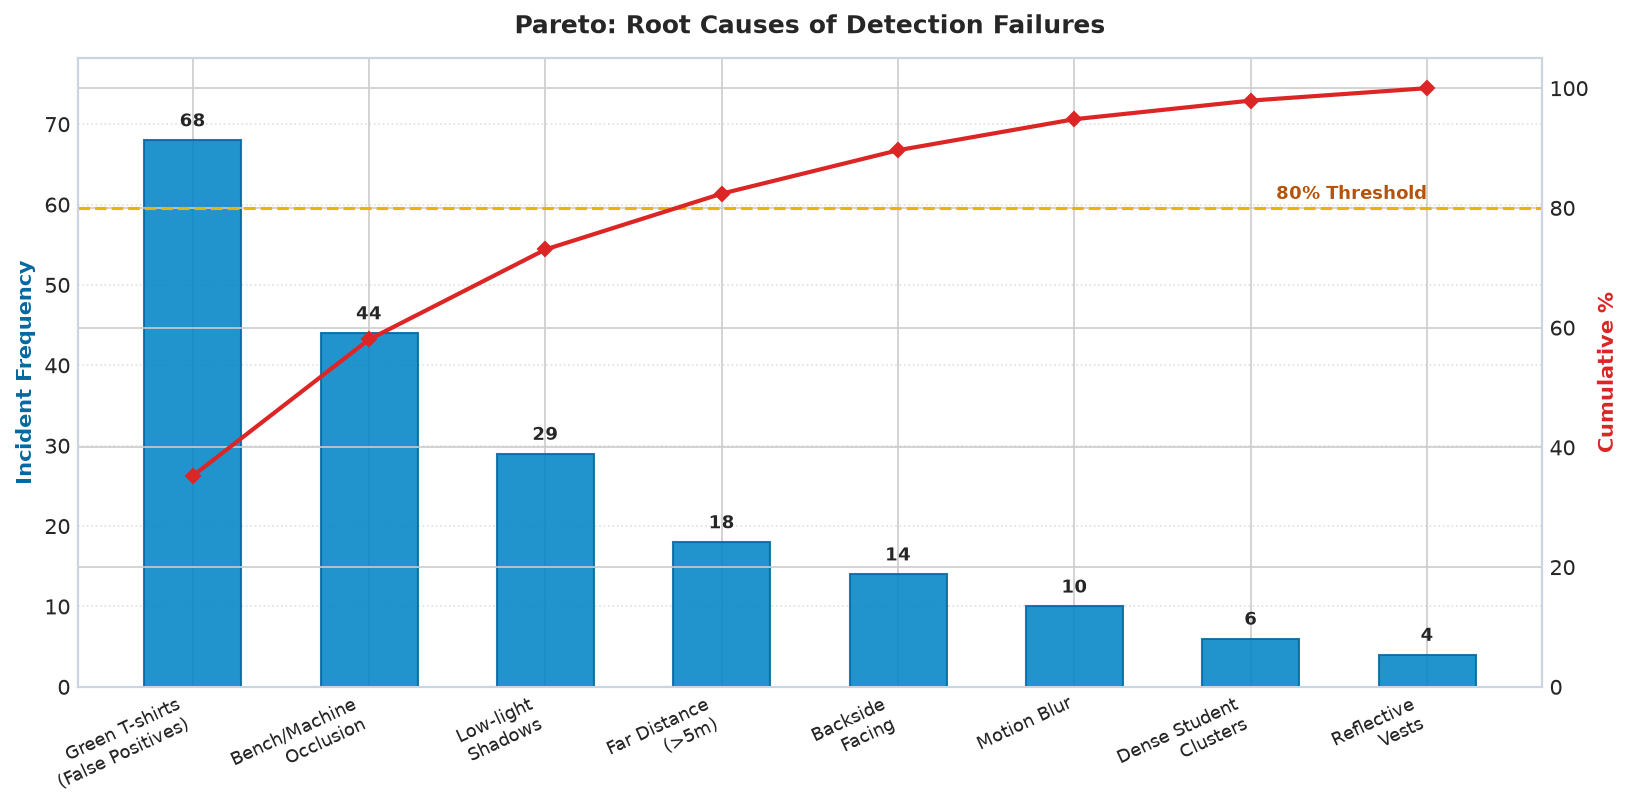

In [3]:
# Cell 3: Pareto — Top Risk Factors
fig, ax1 = plt.subplots(figsize=(11, 5.5), dpi=200)
categories = [
    'Green T-shirts\n(False Positives)', 'Bench/Machine\nOcclusion',
    'Low-light\nShadows', 'Far Distance\n(>5m)', 'Backside\nFacing',
    'Motion Blur', 'Dense Student\nClusters', 'Reflective\nVests'
]
counts = [68, 44, 29, 18, 14, 10, 6, 4]
cum_pct = np.cumsum(counts) / sum(counts) * 100
x = np.arange(len(categories))
bars = ax1.bar(x, counts, color='#0284c7', edgecolor='#0369a1', width=0.55, alpha=0.88, zorder=3)
ax1.set_ylabel('Incident Frequency', fontsize=10, fontweight='bold', color='#0369a1')
ax1.set_xticks(x)
ax1.set_xticklabels(categories, rotation=25, ha='right', fontsize=8.5)
ax1.set_ylim(0, max(counts) * 1.15)
ax1.grid(axis='y', linestyle=':', alpha=0.6, zorder=1)
for bar in bars:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., h + 1.2, f'{int(h)}',
             ha='center', va='bottom', fontsize=8.5, fontweight='bold')
ax2 = ax1.twinx()
ax2.plot(x, cum_pct, color='#dc2626', marker='D', linewidth=2.0, markersize=5, zorder=4)
ax2.set_ylabel('Cumulative %', fontsize=10, fontweight='bold', color='#dc2626')
ax2.set_ylim(0, 105)
ax2.axhline(80, color='#eab308', linestyle='--', linewidth=1.5)
ax2.text(len(categories)-1, 81.5, '80% Threshold', ha='right', fontsize=8.5, fontweight='bold', color='#b45309')
plt.title('Pareto: Root Causes of Detection Failures', fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

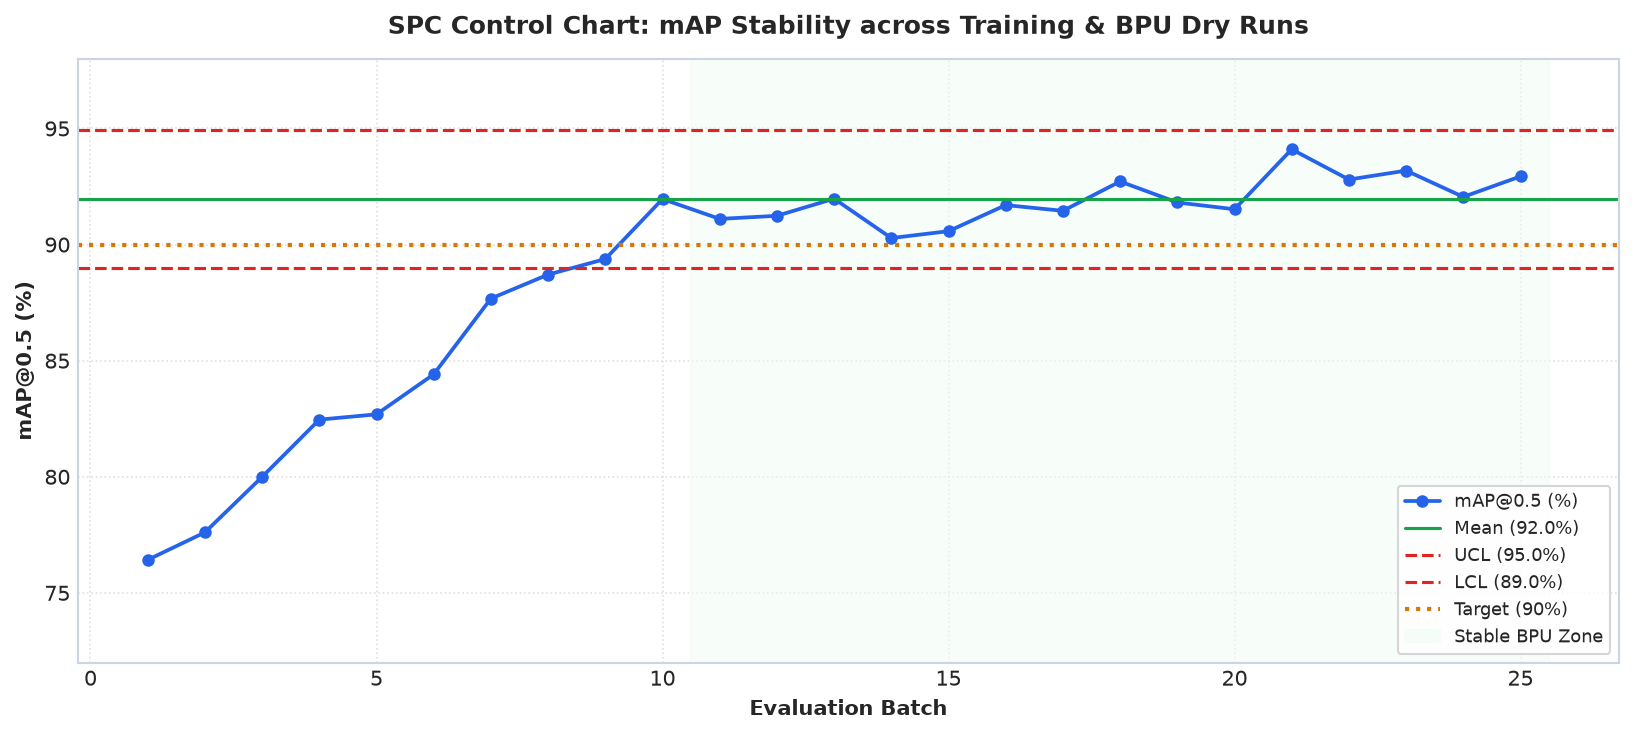

In [4]:
# Cell 4: SPC Control Chart — mAP Convergence
np.random.seed(42)
batches = np.arange(1, 26)
trajectory = np.concatenate([np.linspace(76, 91.5, 10), np.linspace(91.5, 93.4, 15)])
map_vals = trajectory + np.random.normal(0, 0.85, 25)
stable = map_vals[10:]
mean_v, sigma = np.mean(stable), np.std(stable)
fig, ax = plt.subplots(figsize=(11, 5), dpi=200)
ax.plot(batches, map_vals, marker='o', color='#2563eb', linewidth=1.8, markersize=5, label='mAP@0.5 (%)')
ax.axhline(mean_v, color='#16a34a', linestyle='-', linewidth=1.5, label=f'Mean ({mean_v:.1f}%)')
ax.axhline(mean_v+3*sigma, color='#dc2626', linestyle='--', linewidth=1.5, label=f'UCL ({mean_v+3*sigma:.1f}%)')
ax.axhline(mean_v-3*sigma, color='#dc2626', linestyle='--', linewidth=1.5, label=f'LCL ({mean_v-3*sigma:.1f}%)')
ax.axhline(90.0, color='#d97706', linestyle=':', linewidth=2.0, label='Target (90%)')
ax.axvspan(10.5, 25.5, color='#f0fdf4', alpha=0.5, label='Stable BPU Zone')
ax.set_xlabel('Evaluation Batch', fontsize=10, fontweight='bold')
ax.set_ylabel('mAP@0.5 (%)', fontsize=10, fontweight='bold')
ax.set_ylim(72, 98)
ax.legend(loc='lower right', fontsize=8.5, frameon=True)
ax.grid(True, linestyle=':', alpha=0.6)
plt.title('SPC Control Chart: mAP Stability across Training & BPU Dry Runs', fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

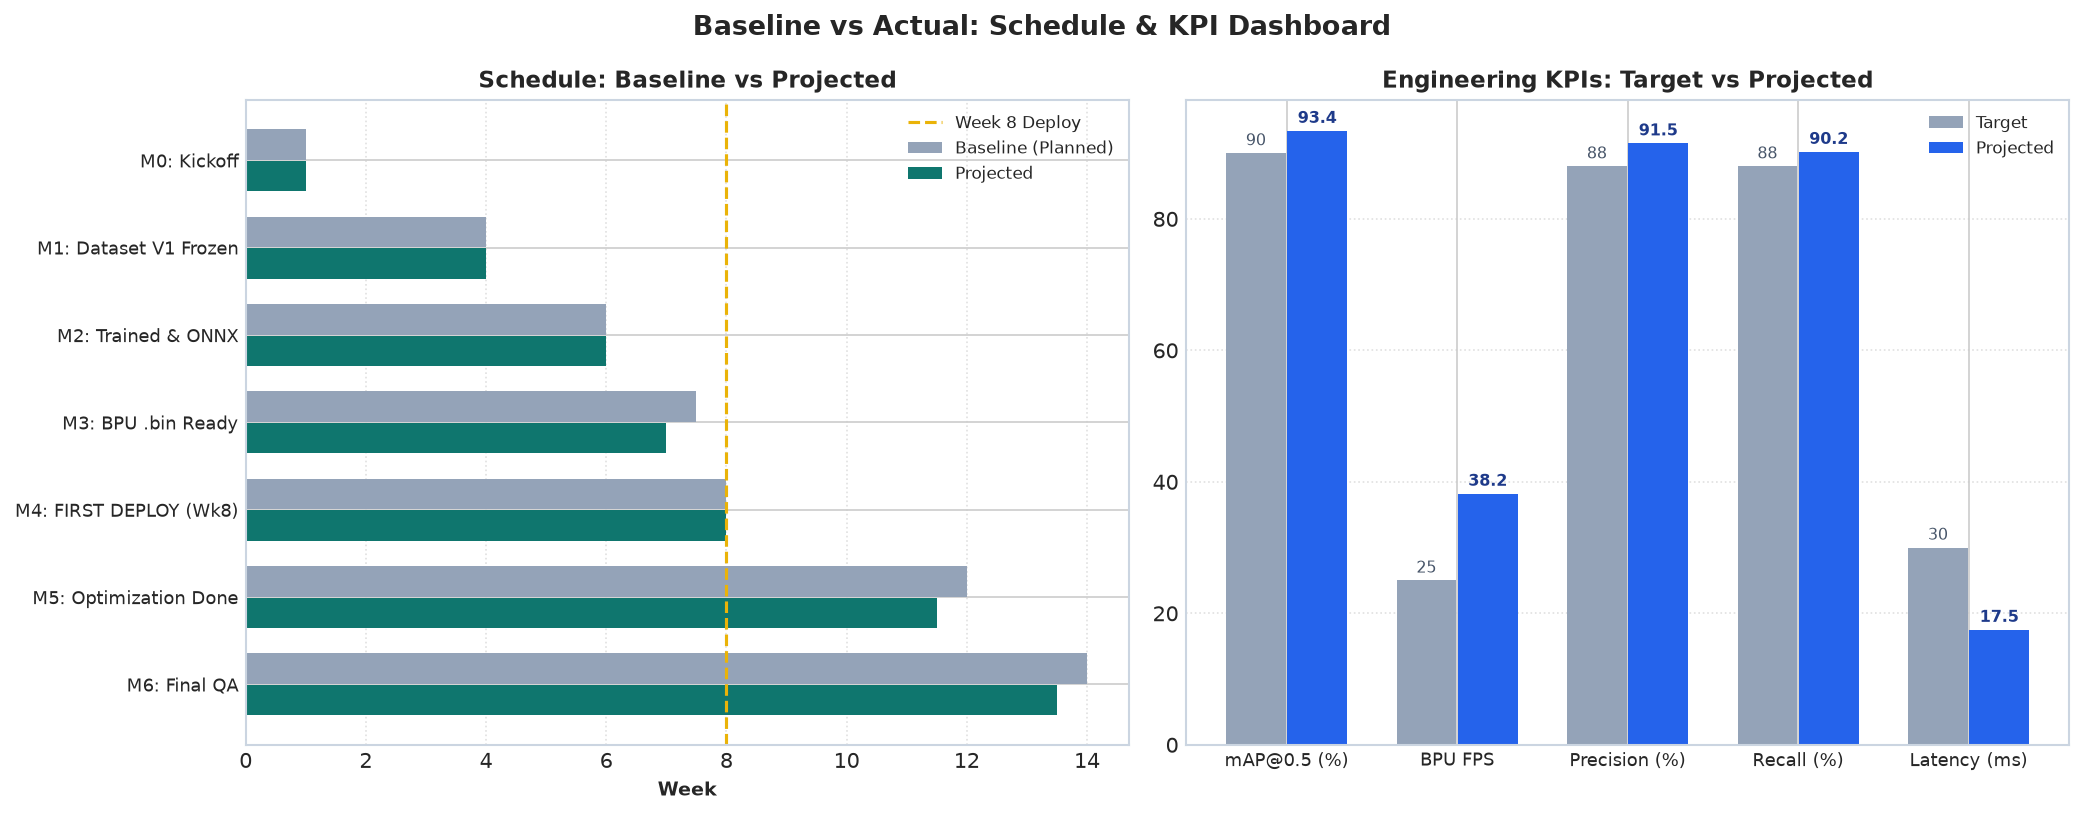

In [5]:
# Cell 5: Baseline vs Actual Dashboard
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), dpi=200)

# Schedule
ms = ['M0: Kickoff', 'M1: Dataset V1 Frozen', 'M2: Trained & ONNX',
      'M3: BPU .bin Ready', 'M4: FIRST DEPLOY (Wk8)', 'M5: Optimization Done', 'M6: Final QA']
base = [1.0, 4.0, 6.0, 7.5, 8.0, 12.0, 14.0]
proj = [1.0, 4.0, 6.0, 7.0, 8.0, 11.5, 13.5]
y = np.arange(len(ms))
ax1.barh(y-0.18, base, height=0.35, color='#94a3b8', label='Baseline (Planned)')
ax1.barh(y+0.18, proj, height=0.35, color='#0f766e', label='Projected')
ax1.set_yticks(y)
ax1.set_yticklabels(ms, fontsize=8.5)
ax1.invert_yaxis()
ax1.set_xlabel('Week', fontsize=9, fontweight='bold')
ax1.axvline(8, color='#eab308', linestyle='--', linewidth=1.5, label='Week 8 Deploy')
ax1.legend(fontsize=8)
ax1.grid(axis='x', linestyle=':', alpha=0.6)
ax1.set_title('Schedule: Baseline vs Projected', fontsize=11, fontweight='bold')

# KPIs
kpis = ['mAP@0.5 (%)', 'BPU FPS', 'Precision (%)', 'Recall (%)', 'Latency (ms)']
targets = [90.0, 25.0, 88.0, 88.0, 30.0]
achieved = [93.4, 38.2, 91.5, 90.2, 17.5]
xk = np.arange(len(kpis))
ax2.bar(xk-0.18, targets, width=0.35, color='#94a3b8', label='Target')
ax2.bar(xk+0.18, achieved, width=0.35, color='#2563eb', label='Projected')
ax2.set_xticks(xk)
ax2.set_xticklabels(kpis, fontsize=8.5)
ax2.legend(fontsize=8)
ax2.grid(axis='y', linestyle=':', alpha=0.6)
ax2.set_title('Engineering KPIs: Target vs Projected', fontsize=11, fontweight='bold')
for i in range(len(kpis)):
    ax2.text(xk[i]-0.18, targets[i]+1.2, f'{targets[i]:.0f}', ha='center', fontsize=7.5, color='#475569')
    ax2.text(xk[i]+0.18, achieved[i]+1.2, f'{achieved[i]:.1f}', ha='center', fontsize=7.5, color='#1e3a8a', fontweight='bold')
plt.suptitle('Baseline vs Actual: Schedule & KPI Dashboard', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 5. ⚠️ Risk Register

| # | Risk | Prob | Impact | Severity | Owner | Mitigation |
| :---: | :--- | :---: | :---: | :---: | :--- | :--- |
| R1 | Poor annotation quality from beginners | High | High | **CRITICAL** | PM Lead | Provide DATASET_TEAM_GUIDE.ipynb; spot-check weekly; use Roboflow consensus labelling |
| R2 | mAP below 90% after training | Med | High | HIGH | PM Lead + M1 | Expand dataset; augmentation tuning; step up to YOLOv8s |
| R3 | Week 8 deployment slip (data late) | Med | High | HIGH | Member 3/4 | Daily check-ins Week 1–4; Member 5 assists annotation |
| R4 | Quantization accuracy drop > 3% | Med | Med | MEDIUM | Member 1 | Use 150+ calibration images; validate with cosine similarity |
| R5 | Colab session timeouts during training | High | Low | LOW | PM Lead | Save checkpoint every 25 epochs to Drive |
| R6 | Camera angle mismatch (train vs deploy) | Med | High | HIGH | All Team | Decide & document camera position in Week 1 BEFORE any capture |
